# N3. k(조각 수) 고르기와 안정성

**목표**
- NMF 의 조각 수 k 를 고르는 방법 세 가지(오차 대 k, consensus·cophenetic, 재표본 안정성·silhouette)를 직접 계산합니다.
- 진짜 k 를 아는 장난감에서 각 방법이 맞히는지, 틀리는지 확인합니다.
- k 를 너무 크게 잡으면 진짜 조각이 쪼개지고, 너무 작게 잡으면 합쳐지는 모습을 봅니다.
- 실제로 쓸 때의 순서를 표로 정리합니다.

**이 노트북이 답하는 질문**: 데이터 안에 재료가 몇 개 있는지 모를 때, k 를 어떻게 정하나?

**같이 볼 것**
- [N2. 알고리즘](lab02_algorithm.ipynb) (KL 손실, 순서 모호함과 헝가리안 짝 맞추기)
- Brunet 등 2004, [PNAS 본문](https://pmc.ncbi.nlm.nih.gov/articles/PMC384712/) "Model selection" 부분 [1]
- Alexandrov 등 2013, [Cell Reports 본문](https://pmc.ncbi.nlm.nih.gov/articles/PMC3588146/) Experimental Procedures [2]

이 노트북의 데이터는 모두 직접 만든 장난감(시뮬레이션) 데이터입니다.

In [1]:
# 그림 도구 (펼치지 않아도 됩니다).
# 팔레트: Okabe-Ito. 조각(component) 번호마다 색 고정 — 1 파랑, 2 주황, 3 초록, 4 빨강, 5 하늘, 6 노랑, 7 이후 회색.
# 데이터 행렬 V 는 회색 농도, 부호 있는 값(PCA 적재량)은 빨강(+)·파랑(−), 핵심 메시지는 자주. (study_build/nmf/_palette.py 와 같음)
import logging, math, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle, Polygon
from IPython.display import display
from scipy.optimize import linear_sum_assignment, nnls
from sklearn.decomposition import NMF, PCA
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.precision", 2)
pd.set_option("display.width", 140)

COMP = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#56B4E9", "#F0E442", "#6B7280", "#9CA3AF", "#374151", "#BBBBBB"]
COMP_NAME = ["blue", "orange", "green", "red", "sky blue", "yellow", "grey", "light grey", "dark grey", "pale grey"]
V_CMAP = "Greys"
SIGNED_CMAP = "RdBu_r"
COL = dict(ink="#222222", muted="#6B7280", grid="#E5E7EB", shade="#F3F4F6", highlight="#CC79A7",
           ok="#009E73", data="#4B5563", none="#D1D5DB", light="#E5E7EB",
           matW="#374151", matH="#9CA3AF", matV="#6B7280")   # 행렬 V, W, H 상자는 회색 계열(조각 색과 섞이지 않게)


def apply_theme():
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5, "mathtext.fontset": "dejavusans",
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white"})


def panel(ax, letter, title):
    """왼쪽 정렬 'A   제목'"""
    ax.set_title(f"{letter}   {title}")


def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    return ax.text(x, y, text, **kw)


def callout(ax, x, y, text, **kw):
    """핵심 메시지 한 줄: 자주색 굵은 글씨, 흰 바탕"""
    kw.setdefault("fontsize", 10); kw.setdefault("color", COL["highlight"]); kw.setdefault("fontweight", "semibold")
    kw.setdefault("bbox", dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9))
    return ax.text(x, y, text, **kw)


def ygrid(ax):
    ax.yaxis.grid(True); ax.set_axisbelow(True)


def formula_strip(ax, parts, y=0.5, fontsize=17, gap=0.03):
    """수식을 조각으로 그린다. parts = [(mathtext, 색 또는 None, 아래 이름표 또는 None), ...]
    이름표가 조각보다 넓으면 그만큼 자리를 더 준다."""
    ax.set_axis_off(); fig = ax.figure
    r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); x = 0.0; items = []
    for tex, color, label in parts:
        tc = COL["muted"] if color == COL["matH"] else (color or COL["ink"])   # 옅은 회색 조각도 글자는 읽히게
        t = ax.text(0, y, tex, fontsize=fontsize, va="center", ha="left", color=tc, transform=ax.transAxes)
        bb = t.get_window_extent(renderer=r).transformed(inv)
        lw = 0.0
        if label:
            lt = ax.text(0, 0, label, fontsize=9.5, fontweight="semibold", transform=ax.transAxes)
            lw = lt.get_window_extent(renderer=r).transformed(inv).width; lt.remove()
        slot = max(bb.width, lw)
        items.append((t, bb, color, label, x + (slot - bb.width) / 2)); x += slot + gap
    shift = (1 - (x - gap)) / 2
    for t, bb, color, label, x0 in items:
        t.set_x(x0 + shift)
        if color:
            ax.add_patch(FancyBboxPatch((x0 + shift - 0.006, bb.y0 - 0.04), bb.width + 0.012, bb.height + 0.08,
                                        boxstyle="round,pad=0,rounding_size=0.02", transform=ax.transAxes,
                                        facecolor=color, alpha=0.13, edgecolor="none", zorder=0))
        if label:
            ax.text(x0 + shift + bb.width / 2, bb.y0 - 0.12, label, ha="center", va="top", fontsize=9.5,
                    color=COL["muted"] if color in (None, COL["matH"]) else color, fontweight="semibold", transform=ax.transAxes)


def show_formula(parts, title=None, height=1.6, width=11):
    """수식 조각 그림만 한 장으로"""
    fig, ax = plt.subplots(figsize=(width, height))
    formula_strip(ax, parts)
    if title:
        ax.text(0.5, 1.05, title, ha="center", va="bottom", fontsize=11.5, fontweight="semibold", transform=ax.transAxes)
    plt.show()


def concept_map(nodes, edges, title="Concept map", size=(11, 3.2)):
    """nodes = {key: (x, y, text, color)}, edges = [(from, to, label)] — 상자와 화살표"""
    fig, ax = plt.subplots(figsize=size)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_axis_off()
    boxes = {}
    for k, (x, y, text, c) in nodes.items():
        boxes[k] = ax.text(x, y, text, ha="center", va="center", fontsize=10, color=COL["ink"], zorder=3,
                           bbox=dict(boxstyle="round,pad=0.45", facecolor=c if c != "white" else "white",
                                     alpha=0.22 if c != "white" else 1, edgecolor=c if c != "white" else COL["muted"],
                                     linewidth=1.0))
    fig.canvas.draw(); r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted()
    ext = {k: t.get_bbox_patch().get_window_extent(r).transformed(inv) for k, t in boxes.items()}

    def edge_point(k, dx, dy):
        b = ext[k]; cx, cy = (b.x0 + b.x1) / 2, (b.y0 + b.y1) / 2
        hw, hh = (b.x1 - b.x0) / 2 + 0.008, (b.y1 - b.y0) / 2 + 0.02
        s = min(hw / abs(dx) if dx else 1e9, hh / abs(dy) if dy else 1e9)
        return cx + dx * s, cy + dy * s

    for a, b, lab in edges:
        ca = ((ext[a].x0 + ext[a].x1) / 2, (ext[a].y0 + ext[a].y1) / 2)
        cb = ((ext[b].x0 + ext[b].x1) / 2, (ext[b].y0 + ext[b].y1) / 2)
        dx, dy = cb[0] - ca[0], cb[1] - ca[1]
        p0 = edge_point(a, dx, dy); p1 = edge_point(b, -dx, -dy)
        ax.annotate("", xy=p1, xytext=p0, xycoords="axes fraction", textcoords="axes fraction",
                    arrowprops=dict(arrowstyle="-|>", color=COL["muted"], lw=1.0, mutation_scale=12,
                                    shrinkA=0, shrinkB=0), zorder=2)
        if lab:
            note(ax, (p0[0] + p1[0]) / 2, (p0[1] + p1[1]) / 2 + 0.05, lab, ha="center", fontsize=8.5,
                 transform=ax.transAxes)
    ax.set_title(title)
    plt.show()


# ---------- 행렬 보여 주기 ----------
def show_matrix(df, name, meaning=None, n=5):
    """표 앞부분과 모양(행 × 열)을 함께 보여 준다"""
    print(f"{name}: {df.shape[0]} rows x {df.shape[1]} columns" + (f"   <- {meaning}" if meaning else ""))
    display(df.head(n).round(3))     # 1e-300 같은 아주 작은 값은 0.000 으로 보인다


def shapes_on(ax, n, m, k, names=("V", "W", "H"), rows="features", cols="samples", comps="components",
              captions=("data", "parts (recipes)", "amounts"), colors=None, fontsize=16):
    """V (n x m) ≈ W (n x k) x H (k x m) 를 실제 숫자로 그린 상자 그림. 크기는 로그 눈금으로 줄여 그린다."""
    sc = lambda v: 0.25 + 0.75 * math.log1p(v) / math.log1p(max(n, m, k, 30))
    hv, wv, wk = sc(n), sc(m), sc(k)
    ax.set_axis_off(); ax.set_aspect("equal")
    colors = colors or (COL["matV"], COL["matW"], COL["matH"])
    nl = chr(10)
    boxes = [(names[0], wv, hv, f"{n} {rows}{nl}x {m} {cols}", captions[0], colors[0]),
             (names[1], wk, hv, f"{n} {rows}{nl}x {k} {comps}", captions[1], colors[1]),
             (names[2], wv, wk, f"{k} {comps}{nl}x {m} {cols}", captions[2], colors[2])]
    top = max(hv, wk) / 2
    x = 0.0
    for i, (nm, w, h, dims, cap, c) in enumerate(boxes):
        ax.add_patch(FancyBboxPatch((x, -h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.02",
                                    facecolor=c, alpha=0.30, edgecolor=c, lw=1.4))
        ax.text(x + w / 2, 0.0, nm, ha="center", va="center", fontsize=fontsize, fontweight="bold", color=COL["ink"])
        ax.text(x + w / 2, -top - 0.08, dims, ha="center", va="top", fontsize=9.5, color=COL["ink"])
        ax.text(x + w / 2, top + 0.06, cap, ha="center", va="bottom", fontsize=9.5, color=COL["ink"], fontweight="semibold")
        x += w + 0.44
        if i < 2:
            ax.text(x - 0.22, 0, "≈" if i == 0 else "×", ha="center", va="center",
                    fontsize=20 if i == 0 else 18, color=COL["ink"])
    ax.set_xlim(-0.05, x - 0.39); ax.set_ylim(-top - 0.45, top + 0.28)


def draw_shapes(n, m, k, title=None, size=(11, 2.9), **kw):
    """상자 그림 한 장"""
    fig, ax = plt.subplots(figsize=size)
    shapes_on(ax, n, m, k, **kw)
    if title:
        ax.set_title(title)
    plt.show()


def heat(ax, M, rows=None, cols=None, cmap=V_CMAP, vmin=None, vmax=None, annotate=False, fmt="{:.0f}",
         fontsize=8.5, cbar=False, label=None):
    """행렬 히트맵. annotate=True 면 칸마다 숫자"""
    M = np.asarray(M, float)
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto", interpolation="nearest")
    if rows is not None:
        ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows, fontsize=9)
    else:
        ax.set_yticks([])
    if cols is not None:
        ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, fontsize=9, rotation=0)
    else:
        ax.set_xticks([])
    if annotate:
        hi = np.nanmax(np.abs(M)) if M.size else 1
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                v = M[i, j]
                dark = (abs(v) > 0.55 * hi) if cmap == V_CMAP else (abs(v) > 0.6 * hi)
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fontsize,
                        color="white" if dark else COL["ink"])
    for s in ax.spines.values():
        s.set_visible(False)
    if cbar:
        cb = plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
        cb.outline.set_visible(False)
        if label:
            cb.set_label(label, fontsize=9)
    return im


# ---------- NMF 계산 도구 ----------
def fro_loss(V, R):
    """제곱 오차(Frobenius 노름의 제곱): sum (V - R)^2"""
    return float(((V - R) ** 2).sum())


def kl_loss(V, R, eps=1e-12):
    """일반화 KL: sum V log(V / R) - V + R  (V = 0 인 칸은 0 log 0 = 0)"""
    R = R + eps
    term = np.where(V > 0, V * np.log(np.where(V > 0, V, 1) / R), 0.0)
    return float((term - V + R).sum())


def nmf_mu(V, k, loss="fro", n_iter=500, seed=0, W0=None, H0=None, eps=1e-12):
    """곱셈 갱신 NMF (Lee & Seung 2001 식 4, 5). 반환: W, H, 매 반복의 손실"""
    rng = np.random.default_rng(seed)
    n, m = V.shape
    scale = math.sqrt(V.mean() / k)
    W = rng.random((n, k)) * scale + 1e-3 if W0 is None else np.array(W0, float).copy()
    H = rng.random((k, m)) * scale + 1e-3 if H0 is None else np.array(H0, float).copy()
    hist = np.empty(n_iter)
    for it in range(n_iter):
        if loss == "fro":
            H *= (W.T @ V) / (W.T @ W @ H + eps)
            W *= (V @ H.T) / (W @ H @ H.T + eps)
            hist[it] = fro_loss(V, W @ H)
        else:
            H *= (W.T @ (V / (W @ H + eps))) / (W.sum(axis=0)[:, None] + eps)
            W *= ((V / (W @ H + eps)) @ H.T) / (H.sum(axis=1)[None, :] + eps)
            hist[it] = kl_loss(V, W @ H)
    return W, H, hist


def normalize_W(W, H):
    """W 의 열을 합 1 로 맞추고 그 배수를 H 로 옮긴다(곱 WH 는 그대로)"""
    s = W.sum(axis=0)
    s[s == 0] = 1
    return W / s, H * s[:, None]


def cosine_matrix(A, B):
    """A 의 열과 B 의 열 사이 코사인 유사도 표 (A 열 수 x B 열 수)"""
    A = A / (np.linalg.norm(A, axis=0, keepdims=True) + 1e-12)
    B = B / (np.linalg.norm(B, axis=0, keepdims=True) + 1e-12)
    return A.T @ B


def match_columns(W_ref, W_est):
    """헝가리안 방법으로 W_est 의 열 순서를 W_ref 에 맞춘다. 반환: 순서, 짝마다 코사인"""
    C = cosine_matrix(W_ref, W_est)
    r, c = linear_sum_assignment(-C)
    order = c[np.argsort(r)]
    return order, C[np.arange(len(order)), order]


apply_theme()

In [2]:
# 이 노트북의 데이터와 계산·그림 함수
from scipy.cluster.hierarchy import linkage, cophenet, leaves_list
from scipy.spatial.distance import squareform
from sklearn.metrics import silhouette_samples
from scipy.special import rel_entr
from scipy.stats import ranksums

N_FEAT, N_SAMP, K_TRUE = 30, 80, 4
CH = [f"ch{i + 1:02d}" for i in range(N_FEAT)]
SMP = [f"s{j + 1:02d}" for j in range(N_SAMP)]


def make_toy(seed=3):
    rng = np.random.default_rng(seed)
    W = rng.dirichlet(np.full(N_FEAT, 0.35), size=K_TRUE).T             # 30 x 4, 열 합 1
    dom = np.repeat(np.arange(K_TRUE), N_SAMP // K_TRUE)                # 표본마다 주된 조각
    mix = np.zeros((K_TRUE, N_SAMP))
    for j in range(N_SAMP):
        mix[:, j] = rng.dirichlet(np.ones(K_TRUE) * 0.5) * 0.3
        mix[dom[j], j] += 0.7
    totals = rng.lognormal(np.log(400), 0.5, N_SAMP)                    # 표본마다 총 개수
    H = mix * totals
    V = rng.poisson(W @ H).astype(float)
    return W, H, V, dom


def fit_kl(V, k, seed, max_iter=3000):
    """scikit-learn KL NMF. 입력 V 는 (특징 x 표본). 반환은 우리 방향: W (특징 x k, 열 합 1), H (k x 표본)"""
    m = NMF(n_components=k, init="random", solver="mu", beta_loss="kullback-leibler", max_iter=max_iter, tol=1e-6,
            random_state=seed)
    E = m.fit_transform(V.T)
    return normalize_W(m.components_.T, E.T)


def refit_H(V, W, n_iter=300):
    """W 를 고정하고 KL 로 H 만 맞춘다 (원래 데이터의 재구성 오차를 잴 때)"""
    H = np.full((W.shape[1], V.shape[1]), V.sum(0).mean() / W.shape[1])
    for _ in range(n_iter):
        H *= (W.T @ (V / (W @ H + 1e-12))) / (W.sum(0)[:, None] + 1e-12)
    return H


def draw_concept_map():
    nodes = {
        "data": (0.10, 0.70, "data V\n(true k unknown)", COL["data"]),
        "err": (0.38, 0.86, "1. error vs k\n(always goes down)", "white"),
        "cons": (0.38, 0.52, "2. consensus /\ncophenetic (Brunet)", "white"),
        "stab": (0.38, 0.18, "3. resampling\nstability (silhouette)", "white"),
        "pick": (0.70, 0.52, "pick k: stable, then the\nsmallest k that fits as well", COL["highlight"]),
        "check": (0.92, 0.52, "check: split?\nmerged?", COL["ok"]),
    }
    edges = [("data", "err", ""), ("data", "cons", ""), ("data", "stab", ""), ("err", "pick", ""),
             ("cons", "pick", ""), ("stab", "pick", ""), ("pick", "check", "")]
    concept_map(nodes, edges, title="Concept map: what N3 covers", size=(11.5, 3.7))


def draw_toy(W, V):
    fig = plt.figure(figsize=(12, 5.2))
    gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.6], wspace=0.22)
    axs = gs[0, 0].subgridspec(K_TRUE, 1, hspace=0.3)
    for c in range(K_TRUE):
        a = fig.add_subplot(axs[c])
        a.bar(np.arange(N_FEAT), W[:, c], color=COMP[c], width=0.8)
        a.set_xticks([]); a.set_ylim(0, W.max() * 1.05); a.set_yticks([])
        a.set_ylabel(f"sig {c + 1}", rotation=0, ha="right", va="center", fontsize=9.5, color=COMP[c], fontweight="semibold")
        if c == 0:
            panel(a, "A", "4 true signatures (30 channels each)")
    a = fig.add_subplot(gs[0, 1])
    heat(a, V / V.sum(axis=0), cmap=V_CMAP)
    a.set_xlabel("80 samples (grouped by their main signature)"); a.set_ylabel("30 channels")
    for b in range(1, K_TRUE):
        a.axvline(b * N_SAMP / K_TRUE - 0.5, color=COL["highlight"], lw=1, ls=":")
    panel(a, "B", "V as shares per sample (each column sums to 1)")
    plt.show()


def draw_resampling(V, j=0, reps=3, seed=11):
    rng = np.random.default_rng(seed)
    fig, ax = plt.subplots(1, reps + 1, figsize=(12, 2.9), sharey=True, gridspec_kw={"wspace": 0.1})
    for r in range(reps + 1):
        x = V[:, j] if r == 0 else rng.poisson(V[:, j])
        ax[r].bar(np.arange(N_FEAT), x, color=COL["data"] if r == 0 else COL["muted"], width=0.8)
        ax[r].set_xticks([]); ygrid(ax[r])
        panel(ax[r], "ABCD"[r], f"sample {SMP[j]}: original" if r == 0 else f"resampled #{r}")
    ax[0].set_ylabel("count")
    callout(ax[reps], 0.5, ax[reps].get_ylim()[1] * 0.97, "same shape,\nnew counting noise", ha="left", va="top", fontsize=9.5)
    plt.show()


def draw_error_vs_k(ks, errs):
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={"wspace": 0.3})
    ax[0].plot(ks, errs, "-o", color=COL["ink"], lw=2, ms=6)
    ax[0].axvline(K_TRUE, color=COL["highlight"], ls=":", lw=1.2)
    ax[0].set_xlabel("k"); ax[0].set_ylabel("best KL error (5 starts)"); ax[0].set_xticks(ks); ygrid(ax[0])
    note(ax[0], K_TRUE + 0.15, errs.max() * 0.95, "true k = 4", color=COL["highlight"], va="top")
    panel(ax[0], "A", "Error always goes down as k grows")
    drop = -np.diff(errs) / errs[:-1]
    ax[1].bar(ks[1:], drop, color=[COL["highlight"] if k == K_TRUE else COL["muted"] for k in ks[1:]], width=0.6)
    ax[1].set_xlabel("k"); ax[1].set_ylabel("error drop from k-1 to k (share)"); ax[1].set_xticks(ks[1:]); ygrid(ax[1])
    callout(ax[1], 7.5, drop.max() * 0.7, "big drops stop after 4,\nbut small drops never stop", ha="center", fontsize=9.5)
    panel(ax[1], "B", "How much each extra component buys")
    plt.show()


def draw_consensus(cons, coph, show=(3, 4, 5, 6)):
    fig = plt.figure(figsize=(12, 3.6))
    gs = fig.add_gridspec(1, len(show) + 2, width_ratios=[1] * len(show) + [0.3, 1.35], wspace=0.45)   # 빈 칸 하나로 E 를 띄움
    heat_axes = []
    for i, k in enumerate(show):
        a = fig.add_subplot(gs[0, i]); C = cons[k]; heat_axes.append(a)
        D = 1 - C; np.fill_diagonal(D, 0)
        o = leaves_list(linkage(squareform(D, checks=False), "average"))
        im = a.imshow(C[np.ix_(o, o)], cmap="Greys", vmin=0.5, vmax=1, interpolation="nearest")
        a.set_xticks([]); a.set_yticks([])
        panel(a, "ABCD"[i], f"consensus, k = {k}")
    cb = fig.colorbar(im, ax=heat_axes, orientation="horizontal", fraction=0.06, pad=0.06, aspect=60, ticks=[0.5, 0.75, 1])
    cb.ax.tick_params(labelsize=8.5); cb.set_label("share of runs together (0.5 or less = white)", fontsize=8.5)
    a = fig.add_subplot(gs[0, -1])
    ks = sorted(coph)
    a.plot(ks, [coph[k] for k in ks], "-o", color=COL["ink"], lw=2)
    a.axvline(K_TRUE, color=COL["highlight"], ls=":", lw=1.2)
    a.set_ylim(0.9, 1.01); a.set_xticks(ks); a.set_xlabel("k"); a.set_ylabel("cophenetic"); ygrid(a)
    callout(a, 6.9, 0.925, "stays at 1 after k = 3:\nno drop to read", ha="right", fontsize=9.5)
    panel(a, "E", "Brunet's criterion")
    plt.show()


def draw_stability(ks, stab_avg, stab_min, err_orig):
    fig, ax = plt.subplots(2, 1, figsize=(10.5, 5.8), sharex=True, gridspec_kw={"hspace": 0.3})
    ax[0].plot(ks, stab_avg, "-o", color=COL["ink"], lw=2, label="average silhouette")
    ax[0].plot(ks, stab_min, "--s", color=COL["muted"], lw=1.6, ms=5, label="worst signature")
    ax[0].axhline(0, color=COL["ink"], lw=0.8); ax[0].axvline(K_TRUE, color=COL["highlight"], ls=":", lw=1.2)
    for yy, lab, xx, ha in [(0.80, "SigProfilerExtractor: average must be > 0.80", ks[-1] + 0.25, "right"),
                            (0.20, "... and worst must be > 0.20", 5.1, "left")]:
        ax[0].axhline(yy, color=COL["muted"], ls=":", lw=1)
        ax[0].text(xx, yy + 0.03, lab, ha=ha, va="bottom", fontsize=8.8, color=COL["muted"])
    ax[0].set_ylabel("stability (silhouette)"); ax[0].set_ylim(-0.95, 1.15); ygrid(ax[0]); ax[0].legend(loc="lower left", fontsize=9)
    callout(ax[0], 2.05, 0.45, "k = 3 and 4: every signature comes back\nthe same in every resample (about 1)", va="center", fontsize=9.5)
    k5 = list(ks).index(5)
    callout(ax[0], 5.12, stab_min[k5] - 0.04, f"k = 5: worst signature falls to {stab_min[k5]:.1f}", ha="left", va="top", fontsize=9.5,
            bbox=None)
    panel(ax[0], "A", "Run NMF on 30 resampled copies; do the signatures repeat?")
    ax[1].plot(ks, err_orig, "-o", color=COL["ink"], lw=2)
    ax[1].axvline(K_TRUE, color=COL["highlight"], ls=":", lw=1.2)
    ax[1].set_xlabel("k"); ax[1].set_ylabel("KL error on original V"); ax[1].set_xticks(ks); ygrid(ax[1])
    panel(ax[1], "B", "Reconstruction error of the averaged signatures")
    plt.show()


def draw_split_merge(W, S6, C6, S3, C3, split_pair, split_true, merged_comp):
    fig, ax = plt.subplots(2, 3, figsize=(12, 5.4), gridspec_kw={"hspace": 0.55, "wspace": 0.25})
    a = ax[0, 0]; heat(a, C6, [f"true {i + 1}" for i in range(K_TRUE)], [f"k6-{c + 1}" for c in range(6)],
                       cmap="Greys", vmin=0, vmax=1, annotate=True, fmt="{:.2f}")
    panel(a, "A", "k = 6 vs truth (cosine)")
    x = np.arange(N_FEAT)
    a = ax[0, 1]
    a.bar(x, W[:, split_true], color=COMP[split_true], width=0.8)
    a.set_xticks([]); ygrid(a); panel(a, "B", f"true signature {split_true + 1}")
    a = ax[0, 2]
    for i, c in enumerate(split_pair):
        lab = f"k6-{c + 1} (cos {C6[split_true, c]:.2f}"
        other = max((t for t in range(K_TRUE) if t != split_true), key=lambda t: C6[t, c])
        if C6[other, c] > 0.6:                                   # 다른 진짜와도 닮았으면 섞인 조각
            lab += f"; {C6[other, c]:.2f} to true {other + 1}"
        a.bar(x + (i - 0.5) * 0.4, S6[:, c], width=0.4, color=COMP[split_true], alpha=1 if i == 0 else 0.45, label=lab + ")")
    a.set_xticks([]); ygrid(a); a.set_ylim(0, S6[:, split_pair].max() * 1.35); a.legend(fontsize=8.5, loc="upper right")
    panel(a, "C", "too big k: k = 6 splits it in two")
    a = ax[1, 0]; heat(a, C3, [f"true {i + 1}" for i in range(K_TRUE)], [f"k3-{c + 1}" for c in range(3)],
                       cmap="Greys", vmin=0, vmax=1, annotate=True, fmt="{:.2f}")
    panel(a, "D", "k = 3 vs truth (cosine)")
    tops = np.argsort(-C3[:, merged_comp])[:2]
    a = ax[1, 1]
    for i, t in enumerate(tops):
        a.bar(x + (i - 0.5) * 0.4, W[:, t], width=0.4, color=COMP[t], label=f"true {t + 1}")
    a.set_xticks([]); ygrid(a); a.legend(fontsize=8.5, loc="upper left")
    panel(a, "E", "too small k: two true signatures ...")
    a = ax[1, 2]
    a.bar(x, S3[:, merged_comp], color=COL["muted"], width=0.8)
    a.set_xticks([]); ygrid(a)
    panel(a, "F", f"... become one k3-{merged_comp + 1}")
    plt.show()

## 개념 지도

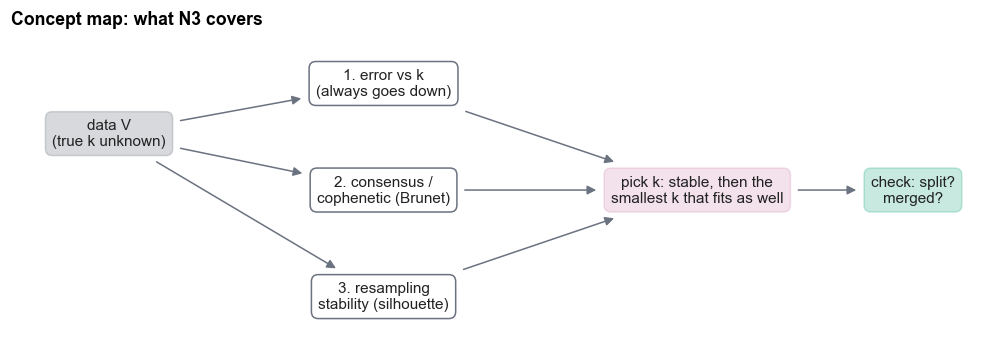

In [3]:
draw_concept_map()

**그림에서 볼 것**
- 같은 데이터에 세 가지 잣대를 씁니다. 1번(오차)은 k 를 늘리면 늘 줄어서 혼자서는 못 고릅니다. 2번(consensus)은 표본 군집이 흔들리는지, 3번(재표본 안정성)은 signature 자체가 되풀이되는지 봅니다.
- 실전에서는 "안정하면서 오차도 충분히 작은 k"를 고릅니다. Alexandrov 2013 은 이를 말로 적었고 [2], SigProfilerExtractor 는 안정성 문턱과 Wilcoxon 검정이라는 숫자 규칙으로 만들었습니다 [3]. 고른 뒤 조각이 쪼개지거나 합쳐지지 않았는지 확인합니다.

## 먼저 알아 둘 것

### 1. 과적합: 조각을 너무 많이 쓰면 잡음까지 설명한다

**한 줄 정의**: 과적합(overfitting)은 모형을 너무 복잡하게 잡아, 진짜 신호가 아니라 그 데이터의 우연한 잡음까지 맞춰 버리는 것입니다(CS329Z A4).

**왜 필요한가**: NMF 에서는 k 가 복잡도입니다. k 를 늘리면 재구성 오차는 늘 줄지만, 늘어난 조각은 진짜 재료를 쪼갠 것이거나 잡음일 수 있습니다.

### 2. 재현성: 같은 답이 또 나오나

**한 줄 정의**: 출발점을 바꾸거나 데이터를 살짝 흔들어(재표본) 다시 돌려도 같은 조각이 나오면 그 답을 믿을 만합니다.

**왜 필요한가**: NMF 는 출발점마다 다른 골짜기에 닿을 수 있고(N2), 회전 모호함도 있습니다. 진짜 재료는 데이터를 흔들어도 되풀이되지만, 잡음을 설명하는 조각은 돌릴 때마다 달라집니다.

### 3. silhouette: 군집이 얼마나 또렷한가

**한 줄 정의**: 한 점의 silhouette 는 $(b-a)/\max(a,b)$ 입니다. a 는 같은 군집 안 점들까지의 평균 거리, b 는 가장 가까운 다른 군집까지의 평균 거리입니다. 1 에 가까우면 또렷하고, 0 근처면 군집이 겹치고, 음수면 다른 군집에 더 가깝습니다 [5].

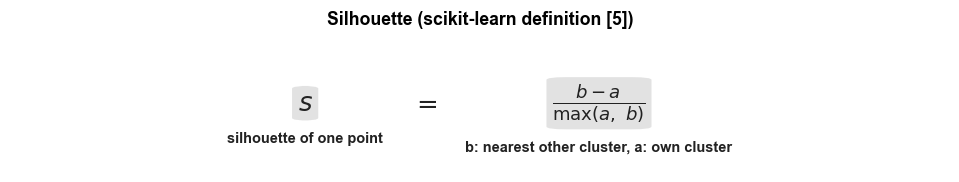

In [4]:
show_formula([(r"$s$", COL["ink"], "silhouette of one point"), (r"$=$", None, None),
              (r"$\frac{b - a}{\max(a,\ b)}$", COL["ink"], "b: nearest other cluster, a: own cluster")],
             title="Silhouette (scikit-learn definition [5])")

| 기호 | 소리 내어 읽기 | 뜻 |
|---|---|---|
| a | "에이" | 같은 군집 안 다른 점들까지의 평균 거리(작을수록 좋음) |
| b | "비" | 가장 가까운 다른 군집의 점들까지의 평균 거리(클수록 좋음) |
| $\max(a, b)$ | "a 와 b 중 큰 것" | 값을 −1 ~ 1 로 맞추는 나눗수 |

**숫자 넣기**: a = 0.1, b = 0.9 이면 s = 0.8/0.9 = 0.89(또렷함). a = 0.5, b = 0.4 이면 s = −0.1/0.5 = −0.2(다른 군집에 더 가까움).

In [5]:
from sklearn.metrics import silhouette_score
pts = np.array([[0.0], [0.1], [0.9], [1.0]]); labs = np.array([0, 0, 1, 1])
s_manual = np.mean([((0.9 + 1.0) / 2 - 0.1) / max((0.9 + 1.0) / 2, 0.1), ((0.8 + 0.9) / 2 - 0.1) / max((0.8 + 0.9) / 2, 0.1)] * 2)
assert abs(silhouette_score(pts, labs) - s_manual) < 1e-12
print("silhouette of 4 points in 2 clear groups:", round(silhouette_score(pts, labs), 3))

silhouette of 4 points in 2 clear groups: 0.889


## 1. 진짜 k 를 아는 장난감

**숫자로 따라가기**: 채널 30개짜리 signature 4개를 만들고, 표본 80개가 각각 하나의 signature 를 70% 이상 쓰고(0.7 에, 나머지 0.3 을 무작위로 나눈 몫이 더해짐) 다른 signature 를 조금씩 섞게 했습니다. 표본마다 총 개수는 100~2,000 정도이고, 칸마다 포아송 잡음을 넣었습니다. 진짜 k = 4 입니다.

In [6]:
W_true, H_true, V, dom = make_toy()
show_matrix(pd.DataFrame(V, index=CH, columns=SMP), "V (counts)", "30 channels x 80 samples")
print("true signatures pairwise cosine:"); display(pd.DataFrame(cosine_matrix(W_true, W_true), index=[f"sig{c+1}" for c in range(4)],
                                                            columns=[f"sig{c+1}" for c in range(4)]).round(2))

V (counts): 30 rows x 80 columns   <- 30 channels x 80 samples


,s01,s02,s03,s04,s05,s06,s07,s08,s09,s10,...,s71,s72,s73,s74,s75,s76,s77,s78,s79,s80
ch01,3.0,3.0,0.0,2.0,3.0,1.0,2.0,0.0,0.0,0.0,...,14.0,7.0,5.0,14.0,13.0,6.0,20.0,9.0,18.0,7.0
ch02,13.0,10.0,27.0,21.0,27.0,29.0,7.0,17.0,11.0,22.0,...,21.0,13.0,4.0,14.0,4.0,5.0,3.0,13.0,7.0,11.0
ch03,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
ch04,5.0,8.0,6.0,10.0,7.0,2.0,9.0,0.0,5.0,1.0,...,61.0,19.0,17.0,63.0,41.0,17.0,56.0,31.0,64.0,50.0
ch05,1.0,2.0,3.0,4.0,5.0,3.0,0.0,2.0,5.0,5.0,...,1.0,0.0,0.0,4.0,1.0,1.0,1.0,3.0,1.0,1.0


true signatures pairwise cosine:


,sig1,sig2,sig3,sig4
sig1,1.00,0.30,0.51,0.49
sig2,0.30,1.00,0.13,0.53
sig3,0.51,0.13,1.00,0.21
sig4,0.49,0.53,0.21,1.00


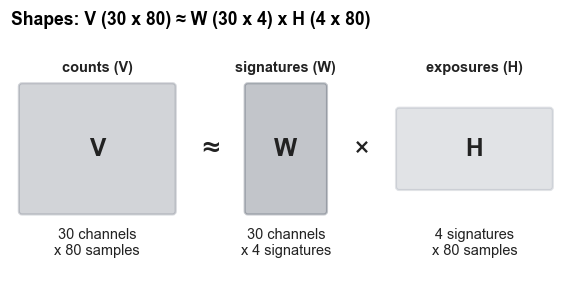

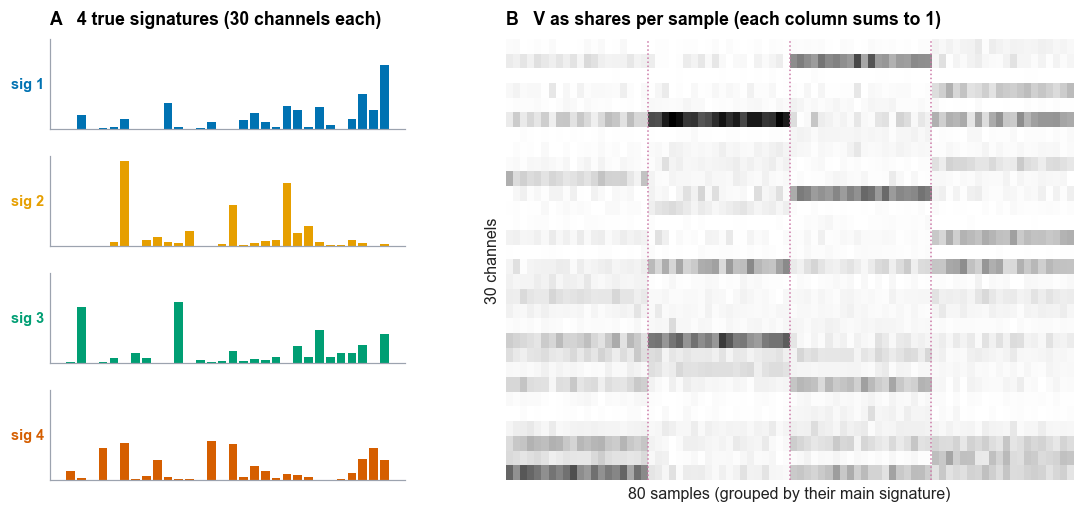

In [7]:
draw_shapes(N_FEAT, N_SAMP, K_TRUE, rows="channels", cols="samples", comps="signatures",
            captions=("counts (V)", "signatures (W)", "exposures (H)"), title="Shapes: V (30 x 80) ≈ W (30 x 4) x H (4 x 80)")
draw_toy(W_true, V)

**그림에서 볼 것**
- A: 진짜 signature 4개입니다. 서로 조금씩 닮았습니다(위 표의 코사인 0.13~0.53).
- B: 데이터 V 를 표본마다 비율로 바꿔(열 합 1) 그렸습니다. 총 개수가 큰 표본이 그림을 덮지 않게 하려는 것입니다. 표본은 주로 쓴 signature 별로 20개씩 묶어 두었습니다(점선). 우리는 이 사실을 모른다고 칩니다.

## 2. 잣대 1: 오차 대 k

**한 줄 정의**: k 를 1 부터 늘려 가며 재구성 오차를 잽니다. 오차가 크게 줄다가 완만해지는 곳("팔꿈치")을 봅니다.

**왜 혼자로는 모자라나**: k 를 늘리면 조각이 많아져 오차는 거의 늘 줄어듭니다. 그래서 "가장 작은 오차"를 고르면 늘 가장 큰 k 를 고르게 됩니다.

In [8]:
ks = np.arange(1, 11)
errs = np.array([min(kl_loss(V, np.matmul(*fit_kl(V, k, s))) for s in range(5)) for k in ks])
print(pd.Series(np.round(errs, 1), index=ks, name="best KL error").to_string())
assert np.all(np.diff(errs) < 0)

1     10167.8
2      5646.7
3      3001.9
4      1050.1
5       983.3
6       919.1
7       856.5
8       798.9
9       749.1
10      703.2


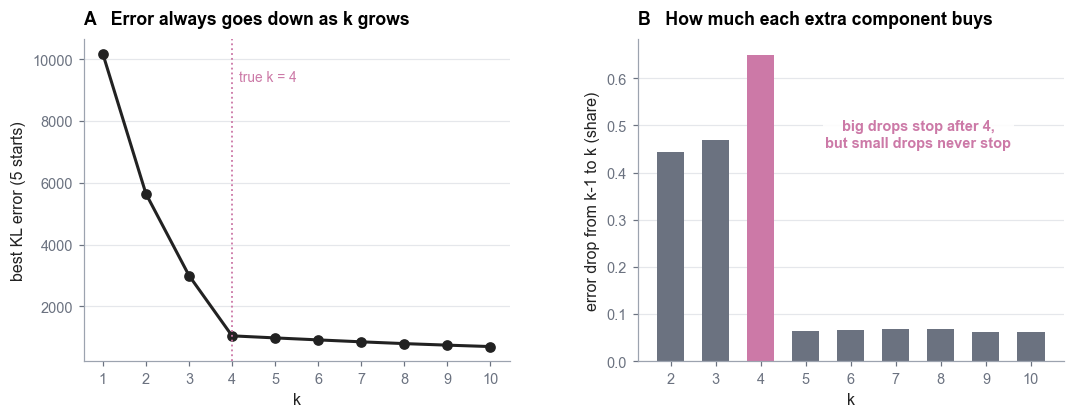

In [9]:
draw_error_vs_k(ks, errs)

**그림에서 볼 것**
- A: 오차는 k = 10 까지 한 번도 올라가지 않습니다.
- B: 한 칸 늘릴 때 줄어드는 몫입니다. k = 4 까지는 크게 줄고(자주색 막대), 그 뒤로는 작게 계속 줄어듭니다. 이 장난감에서는 팔꿈치가 진짜 k 와 맞지만, 실제 데이터에서는 팔꿈치가 흐릿한 경우가 많습니다.

## 3. 잣대 2: consensus 와 cophenetic 상관 (Brunet 2004)

**한 줄 정의**: 같은 k 로 NMF 를 여러 번(출발점만 바꿔) 돌리고, 매번 표본을 "가장 큰 조각" 기준으로 군집에 넣습니다. 두 표본이 같은 군집에 들어간 비율을 모은 표가 consensus 행렬이고, 이 표가 0 과 1 로 또렷할수록 cophenetic 상관이 1 에 가깝습니다 [1].

**식과 근거**: Brunet 등은 한 번 돌릴 때마다 연결 행렬 C(같은 군집이면 1, 아니면 0)를 만들고, 여러 번의 평균 $\bar C$ 를 consensus 행렬이라 했습니다. 보통 20~100번이면 충분했다고 적었습니다. cophenetic 상관 $\rho_k$ 는 $1-\bar C$ 거리와 계층 군집 나무에서 읽은 거리의 Pearson 상관이고, **$\rho_k$ 가 떨어지기 시작하는 k** 를 고르라고 제안했습니다 [1]. 표본은 $H$ 의 열에서 가장 큰 조각의 군집으로 넣습니다 [1]. 여기서는 W 의 열 합을 1 로 맞춘 뒤의 H 로 정했습니다(크기 모호함, N2).

In [10]:
cons, coph = {}, {}
for k in range(2, 8):
    C = np.zeros((N_SAMP, N_SAMP))
    for s in range(30):
        _, H_ = fit_kl(V, k, 100 + s)
        lab = H_.argmax(axis=0)
        C += (lab[:, None] == lab[None, :])
    cons[k] = C / 30
    D = 1 - cons[k]; np.fill_diagonal(D, 0)
    coph[k] = cophenet(linkage(squareform(D, checks=False), "average"), squareform(D, checks=False))[0]
print("cophenetic correlation by k:", {k: round(v, 4) for k, v in coph.items()})
same_grp = dom[:, None] == dom[None, :]
for k in (4, 6):
    print(f"k = {k}: pairs from different true groups ever clustered together: {cons[k][~same_grp].max():.2f};"
          f"  pairs from the same group that split in some runs: {np.mean(cons[k][same_grp] < 1):.0%}")

cophenetic correlation by k: {2: 0.9782, 3: 1.0, 4: 1.0, 5: 1.0, 6: 0.9996, 7: 0.9997}
k = 4: pairs from different true groups ever clustered together: 0.00;  pairs from the same group that split in some runs: 0%
k = 6: pairs from different true groups ever clustered together: 0.00;  pairs from the same group that split in some runs: 76%


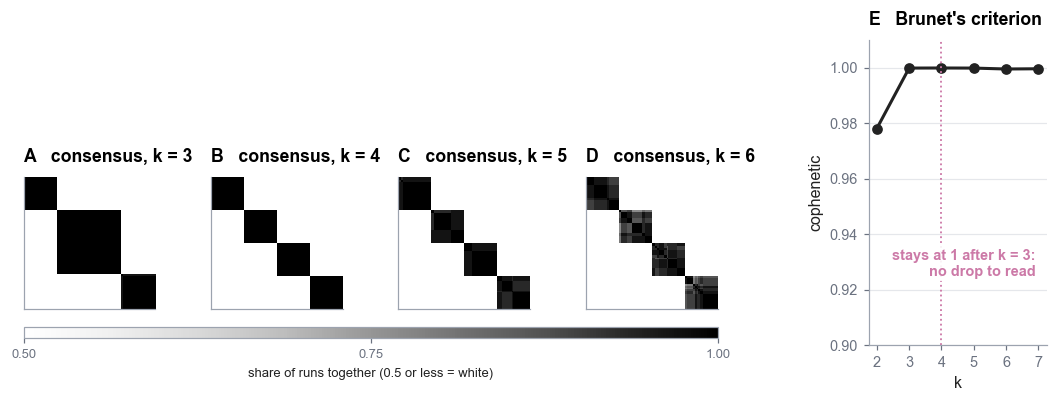

In [11]:
draw_consensus(cons, coph)

**그림에서 볼 것**
- A–D: consensus 행렬을 군집 순서로 다시 놓은 것입니다. 진한 덩어리가 "늘 같이 묶이는 표본들"입니다. 옅은 칸이 잘 보이도록 색은 0.5~1 구간만 펼쳤습니다(0.5 이하는 흰색). k = 5, 6 에서는 덩어리 안에 옅은 칸이 생깁니다. k = 6 에서는 같은 무리 표본 쌍의 76% 가 어떤 실행에서는 갈라졌습니다(위 출력).
- E: 그래도 cophenetic 상관은 k = 3 부터 1 에 가깝게(0.9996 이상) 남아, "떨어지기 시작하는 곳"이 없습니다. **이 장난감에서는 이 잣대가 k 를 고르지 못했습니다.** 이 판단은 이 노트북의 시뮬레이션 결과입니다.
- 왜 그런가: 이 잣대는 **표본의 군집**이 나무 모양으로 깔끔하게 그려지는지를 봅니다. k 를 늘리면 한 무리 안 표본들이 실행마다 두 조각 사이를 오가서 옅은 칸이 생깁니다. 하지만 다른 무리의 표본과는 한 번도 같이 묶이지 않습니다(위 출력의 0.00). 그래서 거리 구조가 "큰 덩어리 안의 작은 덩어리"처럼 층을 이루고, 계층 군집 나무가 그 층을 거의 그대로 다시 그립니다. cophenetic 은 바로 "나무가 거리를 얼마나 똑같이 다시 그리나"를 재므로 1 에 가깝게 남습니다. 표본이 여러 signature 를 고루 섞는 mutational signature 데이터에서는 "가장 큰 조각으로 군집 짓기" 자체가 잘 맞지 않을 수도 있습니다.

**직접 바꿔 보기**: `make_toy` 에서 주된 몫 0.7 을 0.4 로 줄여 보세요. 표본 군집이 흐려지면 cophenetic 이 어떻게 바뀌는지 봅니다.

## 4. 잣대 3: 재표본 안정성 (Alexandrov 2013, SigProfilerExtractor)

**한 줄 정의**: 데이터를 개수 잡음만큼 살짝 흔든 사본을 여러 개 만들고, 사본마다 NMF 를 돌립니다. 모든 사본에서 같은 signature 가 되풀이되면(군집이 또렷하면) 그 k 는 안정합니다. 안정성은 signature 군집의 silhouette 로 잽니다 [2][3]. silhouette 의 거리로 코사인을 쓰는 것은 Alexandrov 2013 의 Step 6 에 적혀 있습니다 [2].

**왜 필요한가**: signature 자체가 되풀이되는지를 직접 보니, 표본이 섞여 있어도 쓸 수 있습니다. Alexandrov 등은 매번 재표본한 데이터에 NMF 를 돌려 과적합을 피한다고 적었습니다 [2].

**재표본은 어떻게**: Alexandrov 2013 은 표본마다 총 개수를 그대로 두고 칸 비율대로 다시 뽑는 Monte Carlo bootstrap 을 썼습니다 [2]. SigProfilerExtractor 는 행렬을 **포아송 재표본**한 뒤 정규화해 NMF 를 돌립니다 [3]. 여기서는 포아송 재표본(칸마다 그 값을 평균으로 하는 포아송에서 새로 뽑기)을 씁니다.

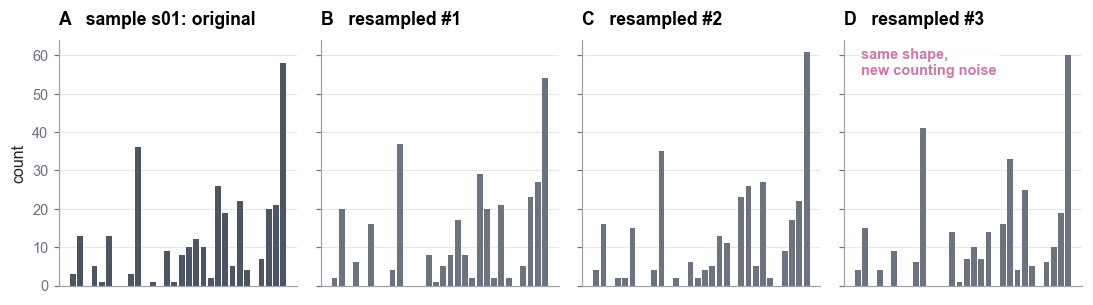

In [12]:
draw_resampling(V)

**그림에서 볼 것**
- A 가 원래 표본 하나, B–D 는 같은 표본을 포아송 재표본한 사본입니다. 모양(어느 채널이 높은가)은 같고, 칸마다 개수만 조금씩 다릅니다. 진짜 signature 는 이런 흔들림에도 되풀이되어야 합니다.

**계산 순서** (SigProfilerExtractor 의 설명을 줄인 것 [3])
1. k 마다 사본 30개(SigProfilerExtractor 기본은 100번 [3])를 만들어 각각 KL NMF 를 돌립니다.
2. 사본마다 나온 k 개 signature 를 헝가리안 방법으로 기준 signature 와 짝지어 군집을 만듭니다. 기준은 군집 평균으로 3번 고쳐 씁니다. SigProfilerExtractor 는 헝가리안 방법을 쓰는 "custom partition clustering" 을 쓰고, silhouette 평균이 1e-12 보다 적게 바뀔 때까지 되풀이합니다 [3]. 아래 코드는 그 생각만 따른 간단판입니다.
3. 모든 signature 의 silhouette(코사인 거리, Alexandrov 2013 Step 6 [2])를 계산해, 평균과 가장 나쁜 군집의 값을 봅니다.
4. 군집 평균(centroid)을 답으로 삼고, 원래 V 의 재구성 오차도 잽니다.

In [13]:
rng_rs = np.random.default_rng(2024)
ks_s = np.arange(2, 9); stab_avg, stab_min, err_orig, centroids, err_samp = [], [], [], {}, {}
for k in ks_s:
    sigs = [fit_kl(rng_rs.poisson(V).astype(float), k, 200 + r)[0] for r in range(30)]
    ref = sigs[0].copy()
    for _ in range(3):                                            # 짝짓기 -> 평균 -> 다시 짝짓기
        labels = []
        for S_ in sigs:
            order, _ = match_columns(ref, S_)                     # ref 의 c 번째 군집 <- S_ 의 order[c] 번째 열
            lab = np.empty(k, int); lab[order] = np.arange(k); labels.append(lab)
        allS = np.hstack(sigs); lab_all = np.concatenate(labels)
        ref = np.column_stack([allS[:, lab_all == c].mean(axis=1) for c in range(k)])
    sil = silhouette_samples(allS.T, lab_all, metric="cosine")
    stab_avg.append(sil.mean()); stab_min.append(min(sil[lab_all == c].mean() for c in range(k)))
    centroids[k] = ref / ref.sum(axis=0)
    R_c = centroids[k] @ refit_H(V, centroids[k])
    err_samp[k] = (rel_entr(V, R_c) - V + R_c).sum(axis=0)          # 표본마다의 KL 오차 (아래 Wilcoxon 검정에 씀)
    err_orig.append(err_samp[k].sum())
    assert np.isclose(err_samp[k].sum(), kl_loss(V, R_c), rtol=1e-6)
stab_avg, stab_min, err_orig = map(np.array, (stab_avg, stab_min, err_orig))
display(pd.DataFrame({"avg silhouette": stab_avg, "worst signature": stab_min, "KL on original V": err_orig}, index=ks_s).round(3))
assert ks_s[np.argmax(stab_avg)] in (3, 4) and stab_min[ks_s == 4][0] > 0.9 and stab_min[ks_s == 5][0] < 0.5

,avg silhouette,worst signature,KL on original V
2,0.88,0.86,5715.05
3,0.99,0.98,3005.34
4,1.00,1.00,1053.17
5,0.65,-0.60,1050.16
6,0.44,-0.44,1046.02
7,0.25,-0.36,1211.76
8,0.23,-0.40,1024.21


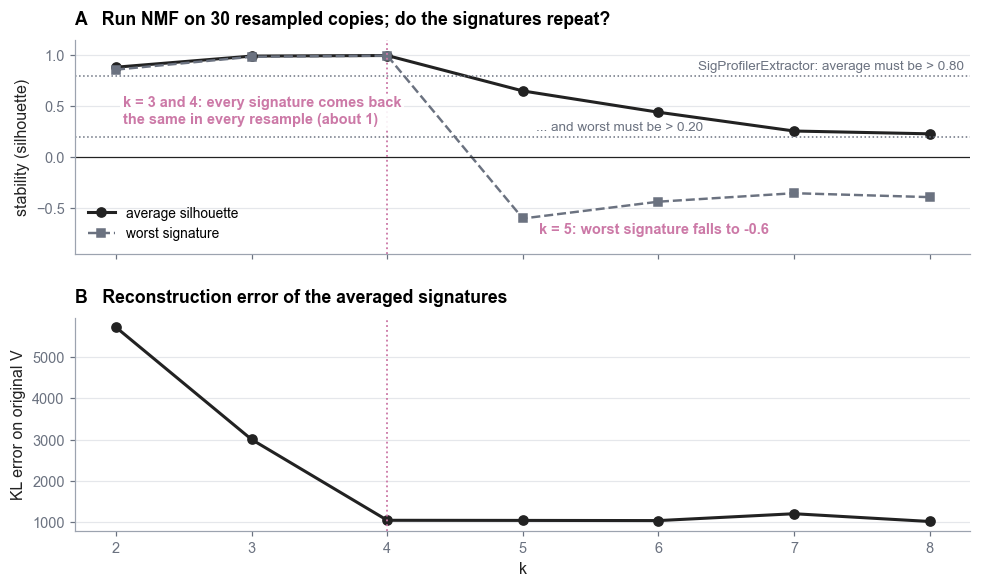

In [14]:
draw_stability(ks_s, stab_avg, stab_min, err_orig)

**그림에서 볼 것**
- A: 검은 실선은 silhouette 평균, 회색 점선은 가장 나쁜 signature 의 값입니다. k = 3, 4 에서는 사본 30개 모두에서 같은 signature 가 나와 둘 다 1 에 가깝습니다. k = 5 부터는 가장 나쁜 signature 의 값이 음수(약 −0.6)로 떨어집니다. 늘어난 조각이 사본마다 다르게 나온다는 뜻입니다. 옅은 가로 점선 둘은 아래에서 쓸 SigProfilerExtractor 의 문턱입니다.
- B: 원래 데이터의 오차는 k = 4 까지 크게 줄고, 그 뒤로는 거의 줄지 않습니다(k = 7 은 불안정한 군집을 평균한 탓에 오히려 커졌습니다).
- 둘을 함께 보면 "안정하면서 오차가 충분히 작은 k" 는 4 입니다. k = 3 도 안정하지만 오차가 훨씬 큽니다. Alexandrov 등도 "추출된 과정이 재현되고 재구성 오차가 낮은 N"을 고른다고 적었습니다 [2]. 이 숫자들은 이 노트북의 시뮬레이션 결과입니다.

### SigProfilerExtractor 의 실제 규칙

Alexandrov 2013 은 "안정하고 오차가 낮은 k"를 말로 적었습니다. SigProfilerExtractor 는 이를 숫자 규칙으로 정했습니다 [3].

| 단계 | 규칙 (전장 유전체(WGS) 기본값) | 뜻 |
|---|---|---|
| 1. 안정한 k 고르기 | silhouette 평균 > 0.80 **그리고** 가장 나쁜 signature > 0.20 (엑솜(WES)은 0.70, 0.10) | 모든 signature 가 사본마다 되풀이되는 k 만 남긴다 |
| 2. 기준 정하기 | 안정한 k 중 가장 큰 k | 가장 잘 맞추는 안정한 답 |
| 3. 작은 k 쪽으로 내려가며 비교 | 표본마다의 재구성 오차를 기준 k 와 Wilcoxon 순위합 검정으로 비교. p < 0.05 가 나오면 멈춤 | "이 작은 k 도 기준만큼 데이터를 설명하나?" |
| 4. 답 | p > 0.05 인 것 중 가장 작은 k. 그런 k 가 없으면 기준 k | 같은 설명력이면 조각이 적은 쪽 |

논문은 "reconstruction errors across all samples" 라고만 적어, 어떤 오차를 쓰는지는 밝히지 않습니다 [3]. 여기서는 표본마다의 KL 오차를 씁니다. 위 결과에 이 규칙을 적용해 봅니다.

In [15]:
rule = pd.DataFrame({"avg silhouette": stab_avg, "worst signature": stab_min}, index=pd.Index(ks_s, name="k"))
rule["stable"] = (rule["avg silhouette"] > 0.80) & (rule["worst signature"] > 0.20)
stable = [int(k) for k in ks_s if rule.loc[k, "stable"]]
k_top = max(stable); k_chosen = k_top; pvals = {}
for k in sorted((k for k in stable if k < k_top), reverse=True):     # 큰 k 부터 작은 k 로 내려가며
    pvals[k] = ranksums(err_samp[k], err_samp[k_top]).pvalue
    if pvals[k] < 0.05:
        break                                                     # 기준만큼 설명하지 못함: 여기서 멈춘다
    k_chosen = k
rule[f"Wilcoxon p vs k = {k_top}"] = [f"{pvals[k]:.1e}" if k in pvals else "" for k in ks_s]
rule["median per-sample KL"] = [round(float(np.median(err_samp[k])), 1) for k in ks_s]
display(rule.round(3))
print("stable k:", stable, "  reference k:", k_top, "  chosen k:", k_chosen)
assert stable == [2, 3, 4] and k_chosen == 4

,avg silhouette,worst signature,stable,Wilcoxon p vs k = 4,median per-sample KL
k,,,,,
2,0.88,0.86,True,,58.3
3,0.99,0.98,True,9.8e-18,26.3
4,1.00,1.00,True,,13.0
5,0.65,-0.60,False,,13.0
6,0.44,-0.44,False,,12.7
7,0.25,-0.36,False,,13.6
8,0.23,-0.40,False,,12.3


stable k: [2, 3, 4]   reference k: 4   chosen k: 4


안정한 k 는 2, 3, 4 이고, 기준은 4 입니다. k = 3 의 표본별 오차는 k = 4 보다 뚜렷하게 커서(p 가 0.05 보다 훨씬 작음) 여기서 멈추고, 답은 **k = 4** 입니다. k = 2 는 비교하지 않습니다(규칙상 멈춘 뒤라서).

> **실제 도구와 다른 점** (이 노트북은 생각을 보이려고 줄인 판입니다)
>
> | | 이 노트북 | SigProfilerExtractor 기본값 [3] |
> |---|---|---|
> | k 범위 | 2~8 | 1~25 |
> | 사본 수 | k 마다 30개 | k 마다 100개 |
> | 재표본 뒤 정규화 | 하지 않음 | 가우시안 혼합 모형(GMM)으로 문턱을 정해, 변이가 아주 많은 표본(hypermutator)이 분해를 끌고 가지 않게 줄임 |
> | 한 번의 NMF | 최대 3,000번 반복, 멈춤 기준 1e-6 (scikit-learn) | 최소 10,000번, 최대 1,000,000번 반복, 멈춤 기준 1e-15 |
> | 군집 고쳐 쓰기 | 3번 | silhouette 평균의 변화가 1e-12 이하가 될 때까지 |
> | 군집 시작점 | 첫 사본의 signature | 무작위 k 개 중심 |
>
> 그래서 이 노트북의 silhouette 값은 실제 도구의 값과 다를 수 있습니다. 규칙의 생김새를 익히는 용도로 보세요.

> **시퀀싱 데이터에서는** SigProfilerExtractor 는 k 를 1~25 로 바꿔 가며 k 마다 100번 NMF 를 돌리고, 매번 행렬을 포아송 재표본·정규화한 뒤 KL 곱셈 갱신으로 분해합니다. 헝가리안 방법을 쓰는 군집으로 안정한 해를 찾고, 그 중심을 답으로 삼아 "입력의 흔들림과 NMF 의 비유일성"에 강하게 만든다고 설명합니다 [3]. copy number signature 논문은 같은 도구로 k 마다 250번을 돌렸습니다 [4].

## 5. k 가 틀리면: 쪼개지거나 합쳐진다

**한 줄 정의**: k 가 진짜보다 크면 진짜 signature 하나가 두 조각으로 쪼개지고, 작으면 두 signature 가 한 조각에 섞입니다.

In [16]:
def best_fit(k, n=5):
    fits = [fit_kl(V, k, s) for s in range(n)]
    return min(fits, key=lambda f: kl_loss(V, f[0] @ f[1]))

S6, E6 = best_fit(6); C6 = cosine_matrix(W_true, S6)
S3, E3 = best_fit(3); C3 = cosine_matrix(W_true, S3)
best_true_for = C6.argmax(axis=0)                          # k=6 조각마다 가장 닮은 진짜 signature
counts = np.bincount(best_true_for, minlength=K_TRUE)
multi = [t for t in range(K_TRUE) if counts[t] >= 2]          # 조각을 둘 이상 받은 진짜 signature
split_true = min(multi, key=lambda t: C6[t, best_true_for == t].mean())   # 그중 조각이 가장 "부분적"인 것
split_pair = np.where(best_true_for == split_true)[0][:2]
merged_comp = int(np.argmax(np.sort(C3, axis=0)[-2]))       # 두 번째로 닮은 진짜와도 코사인이 큰 k=3 조각
print("k=6: how many pieces each true signature gets:", counts)
for c in split_pair:                                         # 쪼개진 조각을 진짜 signature 의 합으로 풀어 보기
    wts = nnls(W_true, S6[:, c])[0]
    print(f"k6-{c + 1} ~ " + " + ".join(f"{w_:.2f} x true{t + 1}" for t, w_ in enumerate(wts) if w_ > 0.05))
combo = S6[:, split_pair] @ E6[split_pair].sum(axis=1)          # 두 조각을 데이터 전체에서 맡은 개수로 가중해 더함
cos_combo = float(cosine_matrix(W_true[:, [split_true]], combo[:, None])[0, 0])
print(f"two pieces added (weighted by their exposures): cosine to true {split_true + 1} =", round(cos_combo, 3))
assert cos_combo > 0.99 and max(C6[t, split_pair].max() for t in range(K_TRUE) if t != split_true) > 0.6
print("k=3: component", merged_comp + 1, "cosine to true signatures:", np.round(C3[:, merged_comp], 2))
assert counts.max() >= 2 and np.sort(C3[:, merged_comp])[-2] > 0.75

k=6: how many pieces each true signature gets: [1 1 2 2]
k6-1 ~ 0.07 x true1 + 0.96 x true4
k6-5 ~ 0.40 x true2 + 0.76 x true4
two pieces added (weighted by their exposures): cosine to true 4 = 0.999
k=3: component 1 cosine to true signatures: [0.81 0.46 0.31 0.9 ]


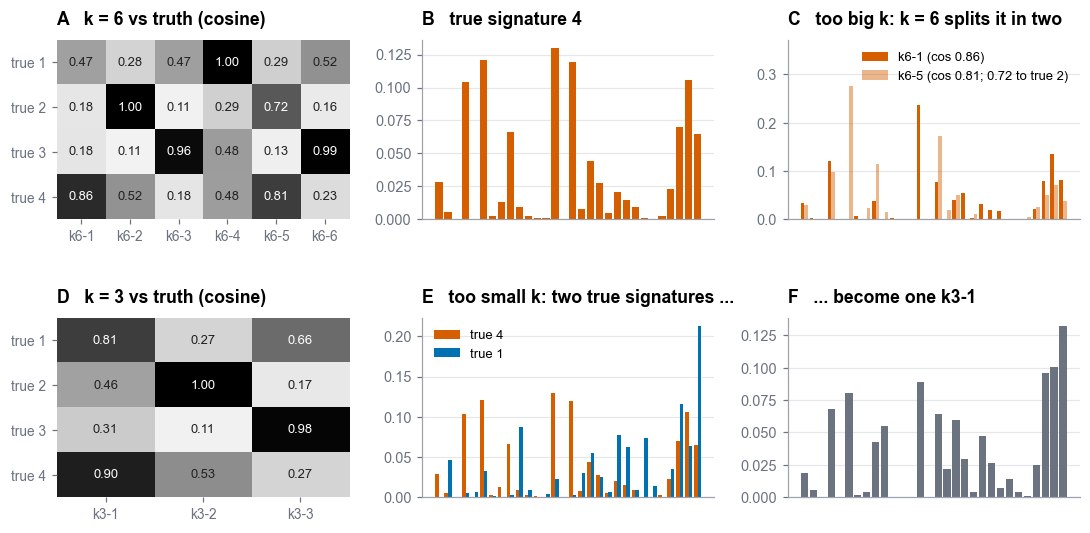

In [17]:
draw_split_merge(W_true, S6, C6, S3, C3, split_pair, split_true, merged_comp)

**그림에서 볼 것**
- A: k = 6 의 각 조각이 진짜 signature 와 얼마나 닮았나(코사인)입니다. 한 진짜 signature 에 높은 값이 두 칸 있으면 그것이 쪼개진 것입니다.
- B–C: 진짜 signature 4(B)와, k = 6 이 만든 두 조각(C)입니다. k6-1 은 진짜 4 와 코사인 0.86 으로 진짜 4 의 한 부분입니다. k6-5 는 진짜 4 와 0.81 이지만 진짜 2 와도 0.72 로 닮아, **진짜 4 에 진짜 2 를 닮은 모양이 섞인 조각**입니다(위 출력에서 진짜 signature 로 풀면 0.40 × 진짜 2 + 0.76 × 진짜 4). 그래도 두 조각을 각자 맡은 개수만큼 더하면 진짜 4 와 코사인 0.999 가 되어, 둘이 진짜 4 를 나눠 가진 것임을 알 수 있습니다.
- A 표를 보면 진짜 signature 3 은 거의 똑같은 조각 두 개(코사인 0.96, 0.99)로 복제되어 그 몫을 나눠 가졌습니다. 쪼개지는 방식은 실행마다 다를 수 있고, 이 결과는 이 노트북의 시뮬레이션 결과입니다.
- D–F: k = 3 에서는 한 조각(F, k3-1)이 진짜 signature 4 와 1 에 동시에 꽤 닮았습니다(D 의 첫 열에 0.90, 0.81). 두 재료가 한데 섞인 것입니다.
- 실제 분석에서는 진짜를 모르니, 추출한 signature 를 알려진 참조(COSMIC 등)와 비교하거나, 같은 k 에서 비슷한 조각이 둘 나오는지 봅니다.

## 6. 실전 순서

| 단계 | 할 일 | 왜 |
|---|---|---|
| 1 | 데이터 모양 확인: 행 = 특징, 열 = 표본인가, 음수 없음, 표본별 총 개수 | 방향 함정(N2), 총 개수가 작은 표본은 잡음이 큼 |
| 2 | 손실 고르기: 개수면 KL | 포아송 우도와 같음(N2) |
| 3 | k 범위를 넓게 훑기(예: 1~15) | 진짜 k 를 모르므로 |
| 4 | k 마다 출발점과 재표본을 바꿔 여러 번(수십~100번) 돌리기 | 비유일성과 잡음을 견디는 답 찾기 [3] |
| 5 | 안정성(silhouette, 가장 나쁜 signature 까지)과 오차를 같이 보기 | 오차만으로는 늘 큰 k 를 고름 [2] |
| 6 | 안정한 k(평균 > 0.80, 가장 나쁜 것 > 0.20) 가운데, 가장 큰 안정한 k 와 표본별 오차가 다르지 않은(Wilcoxon p > 0.05) 가장 작은 k 고르기 | Alexandrov 2013 의 생각 [2] 을 SigProfilerExtractor 가 규칙으로 만든 것 [3] (4절) |
| 7 | 고른 k 에서 쪼개짐·합쳐짐 확인, 알려진 signature 와 코사인 비교 | 5절 |
| 8 | 노출량은 고른 signature 로 다시 맞추기(NNLS) | 행렬 M3, N4 |

4·5·6 단계를 자동으로 해 주는 도구가 SigProfilerExtractor 입니다 [3]. 그 도구가 내놓은 k 도 위 기준으로 한 번 더 확인하면 좋습니다.

## 연습 문제

1. 오차 대 k 그림에서 k = 10 의 오차가 가장 작습니다. 왜 k = 10 을 고르면 안 됩니까?
2. silhouette 의 a = 0.2, b = 0.6 이면 값은 얼마입니까?
3. 표본마다 signature 를 고루 섞는 데이터에서 Brunet 의 consensus(가장 큰 조각으로 군집)가 왜 약할 수 있습니까?
4. k = 5 에서 가장 나쁜 signature 의 silhouette 가 음수입니다. 무슨 뜻입니까?

<details><summary>정답 보기</summary>

1. 오차는 k 를 늘리면 늘 줄어서(과적합) 가장 작은 오차는 늘 가장 큰 k 입니다. 늘어난 조각은 잡음이나 쪼개진 조각일 수 있습니다.
2. (0.6 − 0.2) / 0.6 = 0.67.
3. 표본이 한 군집에 뚜렷이 속하지 않으면 "가장 큰 조각"이 출발점마다 바뀌어 군집 자체가 흐려집니다. 반대로 이 노트북처럼 표본이 한 signature 를 70% 이상 쓰면, signature 가 쪼개져 한 무리 안 표본이 두 조각 사이를 오가도 다른 무리와는 섞이지 않아 cophenetic 이 떨어지지 않습니다(3절). 어느 쪽이든 표본 군집은 signature 가 되풀이되는지를 직접 보여 주지 않습니다.
4. 그 군집의 signature 들이 자기 군집보다 다른 군집과 더 닮았다는 뜻입니다. 사본마다 다른 모양으로 나오는, 믿기 어려운 조각입니다.

</details>

In [18]:
assert abs((0.6 - 0.2) / max(0.2, 0.6) - 0.6667) < 1e-3
print("exercise checks passed")

exercise checks passed


## 정리

- 오차는 k 를 늘리면 늘 줄어, 혼자서는 k 를 고르지 못합니다. 팔꿈치는 참고만 합니다.
- Brunet 의 consensus·cophenetic 은 표본 군집의 흔들림을 봅니다. 이 장난감처럼 표본 군집이 또렷하면 k 를 넘겨 잡아도 떨어지지 않을 수 있습니다.
- 재표본 안정성(silhouette)은 signature 자체가 되풀이되는지를 봐서, 진짜 k 를 넘으면 가장 나쁜 signature 의 값이 크게 떨어집니다.
- "안정하면서 오차가 충분히 작은 k"를 고릅니다. SigProfilerExtractor 는 안정성 문턱(평균 > 0.80, 가장 나쁜 것 > 0.20)과 Wilcoxon 검정으로 이를 정합니다. 고른 뒤 쪼개짐·합쳐짐과 알려진 signature 를 확인합니다.

다음 N4 에서는 이 모든 것을 mutational signature 에 처음부터 끝까지 적용합니다.

## 출처

| 번호 | 출처 | 이 노트북에서 쓴 곳 |
|---|---|---|
| [1] | Brunet J-P, Tamayo P, Golub TR, Mesirov JP (2004). Metagenes and molecular pattern discovery using matrix factorization. *PNAS* 101(12):4164–4169. [doi:10.1073/pnas.0308531101](https://doi.org/10.1073/pnas.0308531101), [PMC384712](https://pmc.ncbi.nlm.nih.gov/articles/PMC384712/). 본문의 연결 행렬·consensus 행렬 정의, "20–100 runs suffice", cophenetic 상관 정의, "select values of k where the magnitude of the cophenetic correlation coefficient begins to fall", 가장 큰 metagene 으로 표본 배정을 확인. | 3절 |
| [2] | Alexandrov LB, Nik-Zainal S, Wedge DC, Campbell PJ, Stratton MR (2013). Deciphering signatures of mutational processes operative in human cancer. *Cell Reports* 3(1):246–259. [PMC3588146](https://pmc.ncbi.nlm.nih.gov/articles/PMC3588146/). Experimental Procedures Step 2(Monte Carlo bootstrap, 총 개수 유지), Step 6 의 "using cosine similarity, the average silhouette width for each of the N clusters is calculated", 결과의 "We select the value of N for which the extracted processes are reproducible and the reconstruction error is low", "Overfitting is avoided by bootstrapping" 을 확인. | 개념 지도, 4·6절 |
| [3] | Islam SMA, Díaz-Gay M 외 (2022). Uncovering novel mutational signatures by de novo extraction with SigProfilerExtractor. *Cell Genomics* 2(11):100179. [PMC9646490](https://pmc.ncbi.nlm.nih.gov/articles/PMC9646490/). "performs 100 independent factorizations … Poisson resampled and normalized … multiplicative update NMF … Kullback-Leibler divergence", "Custom partition clustering, which utilizes the Hungarian algorithm", 중심을 답으로 삼음, silhouette 로 잰 안정성, k 1~25 를 확인. STAR Methods Module 3·4 에서 "average stability above 0.80 with no individual signature having stability below 0.20 (0.70 and 0.10 … whole-exome)", Wilcoxon 순위합 검정으로 작은 k 쪽으로 내려가며 p < 0.05 에서 멈추고 "The stable solution with the lowest number of signatures and a Wilcoxon rank-sum test p value above 0.05 is selected", GMM 정규화(기본), "at least 10,000 iterations … maximum of 1,000,000", 멈춤 기준 10^−15, silhouette 변화 10^−12 까지 되풀이, 무작위 k 개 중심으로 시작을 확인. | 개념 지도, 4·6절 |
| [4] | Steele CD 외 (2022). Signatures of copy number alterations in human cancer. *Nature* 606(7916):984–991. [PMC9242861](https://pmc.ncbi.nlm.nih.gov/articles/PMC9242861/). Methods 의 "250 NMF replicates … on the Poisson resampled data" 를 확인. | 4절 |
| [5] | scikit-learn 1.4 문서, [`sklearn.metrics.silhouette_score`](https://scikit-learn.org/1.4/modules/generated/sklearn.metrics.silhouette_score.html). "(b - a) / max(a, b)", "best value is 1 and the worst value is -1", 음수의 뜻을 확인. 그 밖에 SciPy 1.11 [`cophenet`](https://docs.scipy.org/doc/scipy-1.11.4/reference/generated/scipy.cluster.hierarchy.cophenet.html), [`linear_sum_assignment`](https://docs.scipy.org/doc/scipy-1.11.4/reference/generated/scipy.optimize.linear_sum_assignment.html) 문서. | 먼저 알아 둘 것 3, 3·4절 |

장난감 데이터, 오차·cophenetic·silhouette 값, 쪼개짐·합쳐짐 예는 모두 **이 노트북의 시뮬레이션 결과**입니다.